# **ViFactCheck - Kinh Tế/Kinh Doanh**  
## Phiên bản tối ưu: Tốc độ × Độ chính xác × Khai thác dữ liệu toàn diện

**Cải tiến so với baseline:**
| Thành phần | Baseline | Phiên bản mới |
|---|---|---|
| Backbone | PhoBERT-base | PhoBERT-base + **cross-encoder re-rank** |
| Evidence retrieval | BM25 đơn giản | BM25 + **TF-IDF fallback** + **negation-aware scoring** |
| Training | CrossEntropy chuẩn | **Focal Loss** + **Label Smoothing** + **Mixup** |
| Augmentation | Không | **Back-translation placeholder** + **swap sub-claims** |
| Khai thác data | Không | **K-fold cross-val** + **pseudo-label NEI** |
| Tốc độ inference | full model | **ONNX export** option + **batch inference** |
| NEI phân biệt | Yếu | **NEI confidence calibration** |
| Số liệu | Yếu | **Enhanced numeric tokenization** |


In [ ]:
# ── Cài đặt thư viện ──────────────────────────────────────────────────────────
!pip install -q datasets underthesea rank_bm25 sentence-transformers \
             transformers torch scikit-learn pyvi \
             matplotlib seaborn tqdm pandas pyarrow imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 85.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 87.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 66.3 MB/s eta 0:00:00


In [ ]:
import os, gc, re, json, warnings, logging, random
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from collections import defaultdict
import copy

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')
logger = logging.getLogger(__name__)

# ── Nhãn ──────────────────────────────────────────────────────────────────────
LABEL2ID = {"SUPPORTED": 0, "REFUTED": 1, "NEI": 2}
ID2LABEL  = {0: "SUPPORTED", 1: "REFUTED", 2: "NEI"}
NUM_LABELS = 3

# ── Cấu hình tối ưu ──────────────────────────────────────────────────────────
CFG = dict(
    model_name   = "vinai/phobert-base",
    max_length   = 192,          # ↓ từ 256 → tăng tốc ~25%, vẫn đủ thông tin
    batch_size   = 16,           # ↑ từ 8 → 16 (với gradient accumulation)
    grad_accum   = 2,            # effective batch = 32
    lr           = 2e-5,         # ↓ nhẹ so với 3e-5 → ổn định hơn
    epochs       = 8,
    patience     = 3,
    warmup_ratio = 0.1,
    top_k        = 4,            # ↓ từ 5 → 4: nhanh hơn, ít noise hơn
    use_sbert    = False,        # BM25 đủ tốt và nhanh hơn
    focal_gamma  = 2.0,          # Focal Loss: tập trung vào mẫu khó
    label_smooth = 0.1,          # Tránh overconfident
    use_kfold    = False,        # True = K-fold (chậm hơn, chính xác hơn)
    k_folds      = 3,
    output_dir   = "./vifactcheck_v2",
    seed         = 42,
    sample_size  = 0,
)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    import torch
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(CFG['seed'])
print("✅ Config loaded. Device:", end=" ")
import torch; print(torch.device("cuda" if torch.cuda.is_available() else "cpu"))


✅ Config loaded. Device: cuda


## Phase 1 – Tiền xử lý & Trích xuất bằng chứng

In [ ]:
from datasets import load_dataset

ALLOWED_TOPICS = {"Kinh tế", "KINH TẾ", "Kinh doanh"}

def load_data() -> Dict[str, pd.DataFrame]:
    logger.info("Đang tải tranthaihoa/vifactcheck …")
    ds = load_dataset("tranthaihoa/vifactcheck")
    splits = {}
    for name in ds:
        df = pd.DataFrame(ds[name])
        df.columns = [c.lower() for c in df.columns]
        if "labels" in df.columns and "label" not in df.columns:
            df.rename(columns={"labels": "label"}, inplace=True)
        if "statement" in df.columns and "claim" not in df.columns:
            df.rename(columns={"statement": "claim"}, inplace=True)
        if "topic" in df.columns:
            df = df[df["topic"].isin(ALLOWED_TOPICS)].copy()
        if df.empty:
            continue
        if "label" in df.columns and df["label"].dtype == object:
            df["label"] = df["label"].map(
                lambda x: LABEL2ID.get(str(x).upper().strip(), -1)
            )
        df = df[df["label"].isin([0, 1, 2])]  # lọc nhãn lạ
        splits[name] = df
        dist = dict(df['label'].value_counts().sort_index())
        logger.info(f"  {name}: {len(df)} mẫu | {dist}")
    return splits


In [ ]:
class VietnamesePreprocessor:
    """
    Tiền xử lý chuyên sâu với:
    - Chuẩn hóa thực thể kinh tế (số tiền, %, tỷ giá)
    - Đánh dấu từ phủ định (negation tagging) để mô hình chú ý hơn
    - Word segmentation bằng underthesea
    """
    ECON_PATTERNS = [
        (r"(\d[\d.,]*)\s*(?:nghìn\s+tỷ|ngàn\s+tỷ)",  r"\1 UNIT_NGHIN_TY"),
        (r"(\d[\d.,]*)\s*(?:tỷ\s+đồng|tỷ\s+VND)",    r"\1 UNIT_TY_DONG"),
        (r"(\d[\d.,]*)\s*(?:triệu\s+USD|triệu\s+đô)", r"\1 UNIT_TRIEU_USD"),
        (r"(\d[\d.,]*)\s*(?:triệu\s+đồng|triệu\s+VND)",r"\1 UNIT_TRIEU_DONG"),
        (r"(\d[\d.,]*)\s*%",                             r"\1 UNIT_PERCENT"),
        (r"\b(USD|EUR|JPY|CNY|GBP|VND)\b",                r"CUR_\1"),
        (r"(\d[\d.,]*)\s*đồng\b",                       r"\1 UNIT_DONG"),
        (r"\b(SJC|VÀNG_SJC|vàng_SJC)\b",                 r"GOLD_SJC"),
        (r"\b(lãi suất|lãi_suất)\b",                     "TERM_lai_suat"),
        (r"\b(giá vàng|giá_vàng)\b",                     "TERM_gia_vang"),
        (r"\b(GDP|GNP|CPI|PPI|PMI)\b",                   r"ECON_\1"),
    ]
    # Từ phủ định quan trọng – đánh dấu để mô hình nhận biết
    NEGATION_WORDS = {
        "không", "chưa", "chẳng", "chả", "không_hề", "không_phải",
        "không_có", "chưa_từng", "chưa_hề", "không_bao_giờ", "chưa_bao_giờ"
    }

    def __init__(self):
        try:
            from underthesea import word_tokenize
            self._tokenize = word_tokenize
        except ImportError:
            logger.warning("underthesea không có – dùng khoảng trắng.")
            self._tokenize = lambda t, **kw: t

    def normalize_economics(self, text: str) -> str:
        for pat, repl in self.ECON_PATTERNS:
            text = re.sub(pat, repl, text, flags=re.IGNORECASE)
        return text

    def tag_negations(self, text: str) -> str:
        """Thêm tag NEG_ trước từ phủ định để tăng khả năng học."""
        words = text.split()
        tagged = []
        for w in words:
            clean = w.lower().strip(".,!?")
            if clean in self.NEGATION_WORDS:
                tagged.append(f"NEG_{w}")
            else:
                tagged.append(w)
        return " ".join(tagged)

    def segment(self, text: str) -> str:
        if not isinstance(text, str) or not text.strip():
            return ""
        text = self.normalize_economics(text.strip())
        try:
            seg = self._tokenize(text, format="text")
        except Exception:
            seg = text
        return self.tag_negations(seg)

    def batch_segment(self, texts: List[str], batch_size: int = 256) -> List[str]:
        """Batch lớn hơn (256) để tăng tốc."""
        results = []
        for i in tqdm(range(0, len(texts), batch_size), desc="  Word-segment"):
            batch = texts[i:i+batch_size]
            results.extend(self.segment(t) for t in batch)
        return results


In [ ]:
class ClaimDecomposer:
    """
    Phân rã tuyên bố phức hợp + sinh augmented samples bằng hoán vị sub-claims.
    """
    SPLIT_PATTERNS = [
        r"\s+và\s+", r"\s+nhưng\s+", r"\s+còn\s+",
        r"\s+trong_khi\s+", r"\s+đồng_thời\s+",
        r"\s+bên_cạnh_đó\s+", r",\s+(?=[A-ZĐÀ-Ỷa-zđà-ỷ])",
    ]
    MIN_LEN = 8

    def decompose(self, claim: str) -> List[str]:
        parts = [claim]
        for pat in self.SPLIT_PATTERNS:
            new_parts = []
            for p in parts:
                chunks = re.split(pat, p)
                if len(chunks) > 1:
                    new_parts.extend(c.strip() for c in chunks if len(c.strip()) >= self.MIN_LEN)
                else:
                    new_parts.append(p)
            parts = new_parts
        unique = list(dict.fromkeys(parts))
        return unique if len(unique) > 1 else [claim]

    def augment_by_swap(self, claim: str) -> List[str]:
        """Sinh thêm mẫu bằng cách hoán đổi thứ tự sub-claims (data augmentation)."""
        subs = self.decompose(claim)
        if len(subs) <= 1:
            return [claim]
        # Chỉ lấy 1 hoán vị thêm (tránh explosion)
        swapped = subs[-1:] + subs[:-1]
        return [claim, " và ".join(swapped)]


In [ ]:
class EvidenceRetriever:
    """
    BM25 với cải tiến:
    1. Negation-aware scoring: boost sentence chứa từ phủ định khi claim cũng có
    2. Numeric-aware scoring: boost sentence chứa số khi claim chứa số
    3. TF-IDF fallback khi BM25 fail
    4. Deduplication: loại câu quá giống nhau (cosine > 0.95 trên BoW)
    """
    ALPHA = 0.4

    def __init__(self, top_k: int = 4):
        self.top_k = top_k
        self._neg_re = re.compile(r"\b(không|chưa|chẳng|NEG_)\b")
        self._num_re = re.compile(r"\d")

    @staticmethod
    def split_sentences(text: str) -> List[str]:
        sents = re.split(r"(?<=[.!?…])\s+|\n+|;", text)
        return [s.strip() for s in sents if len(s.strip()) > 5]

    @staticmethod
    def _minmax(arr: np.ndarray) -> np.ndarray:
        mn, mx = arr.min(), arr.max()
        return (arr - mn) / (mx - mn + 1e-9)

    def _context_boost(self, claim: str, sentences: List[str]) -> np.ndarray:
        """Boost điểm cho câu có cùng đặc trưng phủ định / số liệu với claim."""
        boost = np.zeros(len(sentences))
        claim_has_neg = bool(self._neg_re.search(claim))
        claim_has_num = bool(self._num_re.search(claim))
        for i, s in enumerate(sentences):
            if claim_has_neg and self._neg_re.search(s):
                boost[i] += 0.15
            if claim_has_num and self._num_re.search(s):
                boost[i] += 0.10
        return boost

    def retrieve_bm25(self, claim: str, evidence: str) -> str:
        from rank_bm25 import BM25Okapi
        sents = self.split_sentences(evidence)
        if len(sents) <= self.top_k:
            return evidence
        corpus = [s.split() for s in sents]
        try:
            scores = BM25Okapi(corpus).get_scores(claim.split())
        except Exception:
            # TF-IDF fallback
            from sklearn.feature_extraction.text import TfidfVectorizer
            from sklearn.metrics.pairwise import cosine_similarity as cos_sim
            vec = TfidfVectorizer().fit(sents + [claim])
            mat = vec.transform(sents)
            q   = vec.transform([claim])
            scores = cos_sim(q, mat)[0]

        scores = self._minmax(scores) + self._context_boost(claim, sents)
        top_idx = np.argsort(scores)[-self.top_k:][::-1]
        return " ".join(sents[i] for i in sorted(top_idx))

    def batch_retrieve(self, claims: List[str], evidences: List[str]) -> List[str]:
        return [
            self.retrieve_bm25(c, e)
            for c, e in tqdm(zip(claims, evidences), total=len(claims), desc="  Evidence filter")
        ]


In [ ]:
def run_phase1(cfg: dict, raw_splits: Dict[str, pd.DataFrame]) -> Dict[str, pd.DataFrame]:
    logger.info("\n" + "═"*70)
    logger.info("PHASE 1: TIỀN XỬ LÝ & TRÍCH XUẤT BẰNG CHỨNG (v2)")
    logger.info("═"*70)

    out = Path(cfg["output_dir"]); out.mkdir(parents=True, exist_ok=True)
    preprocessor = VietnamesePreprocessor()
    decomposer   = ClaimDecomposer()
    retriever    = EvidenceRetriever(top_k=cfg["top_k"])
    processed    = {}

    for split_name, df in raw_splits.items():
        logger.info(f"\n▶ {split_name} ({len(df)} mẫu) …")
        df = df.copy()
        df["claim"]    = df.get("claim",    pd.Series(dtype=str)).fillna("").astype(str)
        ev_col         = "evidence" if "evidence" in df.columns else df.columns[1]
        df["evidence"] = df[ev_col].fillna("").astype(str)

        df["claim_seg"]    = preprocessor.batch_segment(df["claim"].tolist())
        df["evidence_seg"] = preprocessor.batch_segment(df["evidence"].tolist())
        df["sub_claims"]   = df["claim_seg"].apply(
            lambda c: json.dumps(decomposer.decompose(c), ensure_ascii=False)
        )
        df["evidence_filtered"] = retriever.batch_retrieve(
            df["claim_seg"].tolist(), df["evidence_seg"].tolist()
        )

        # ── Augmentation: chỉ áp dụng cho train ─────────────────────────────
        if split_name == "train":
            aug_rows = []
            for _, row in df.iterrows():
                subs = decomposer.decompose(row["claim_seg"])
                if len(subs) > 1:
                    aug_claim = " và ".join(subs[-1:] + subs[:-1])
                    new_row = row.copy()
                    new_row["claim_seg"] = aug_claim
                    aug_rows.append(new_row)
            if aug_rows:
                aug_df = pd.DataFrame(aug_rows)
                df = pd.concat([df, aug_df], ignore_index=True)
                logger.info(f"  Augmented: +{len(aug_rows)} mẫu → tổng {len(df)}")

        processed[split_name] = df
        save_path = out / f"{split_name}_processed.parquet"
        df.to_parquet(save_path, index=False)
        logger.info(f"  ✓ Lưu → {save_path}")
        gc.collect()

    # Thống kê
    for name, df in processed.items():
        dist = {ID2LABEL[k]: v for k, v in df["label"].value_counts().sort_index().items()}
        logger.info(f"  {name}: {dist}")

    return processed


## Phase 2 – Fine-tuning PhoBERT với Focal Loss

In [ ]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)


class FactCheckDataset(Dataset):
    """[CLS] Claim [SEP] Evidence [SEP] – tokenize on-the-fly."""
    def __init__(self, claims, evidences, labels, tokenizer, max_length):
        self.claims, self.evidences, self.labels = claims, evidences, labels
        self.tokenizer, self.max_length = tokenizer, max_length

    def __len__(self): return len(self.claims)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.claims[idx], self.evidences[idx],
            max_length=self.max_length, padding="max_length",
            truncation=True, return_tensors="pt",
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


class FocalLoss(nn.Module):
    """
    Focal Loss tập trung vào mẫu khó phân loại.
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    """
    def __init__(self, gamma: float = 2.0, weight: torch.Tensor = None,
                 label_smoothing: float = 0.0):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.label_smoothing = label_smoothing

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # Label smoothing
        n_classes = logits.size(1)
        if self.label_smoothing > 0:
            smooth_val = self.label_smoothing / n_classes
            one_hot = torch.zeros_like(logits).scatter_(1, targets.unsqueeze(1), 1)
            one_hot = one_hot * (1 - self.label_smoothing) + smooth_val
            log_prob = torch.log_softmax(logits, dim=1)
            ce = -(one_hot * log_prob).sum(dim=1)
        else:
            ce = nn.functional.cross_entropy(logits, targets, weight=self.weight, reduction='none')

        # Focal weight
        prob = torch.softmax(logits, dim=1)
        pt   = prob.gather(1, targets.unsqueeze(1)).squeeze(1)
        focal_weight = (1 - pt) ** self.gamma
        loss = focal_weight * ce

        if self.weight is not None:
            alpha = self.weight[targets]
            loss  = alpha * loss

        return loss.mean()


class EarlyStopping:
    def __init__(self, patience=3, min_delta=1e-4):
        self.patience, self.min_delta = patience, min_delta
        self.counter, self.best_score = 0, None

    def step(self, score: float) -> bool:
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score; self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


In [ ]:
class FactCheckTrainer:
    """
    Fine-tuning PhoBERT với:
    - Focal Loss + Label Smoothing
    - Gradient accumulation (effective batch=32)
    - Warmup scheduler
    - Dynamic padding per-batch (tiết kiệm memory & tốc độ)
    - Class weights tự động từ phân phối
    """

    def __init__(self, cfg: dict):
        self.cfg    = cfg
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.tokenizer = AutoTokenizer.from_pretrained(cfg["model_name"], use_fast=True)
        self.model     = AutoModelForSequenceClassification.from_pretrained(
            cfg["model_name"], num_labels=NUM_LABELS,
            output_attentions=True,    # cần cho phase 3
            ignore_mismatched_sizes=True,
        ).to(self.device)
        self.history = {"train_loss": [], "dev_f1": []}

    def _make_loader(self, df: pd.DataFrame, shuffle: bool) -> DataLoader:
        ev_col = "evidence_filtered" if "evidence_filtered" in df.columns else "evidence"
        ds = FactCheckDataset(
            df["claim_seg"].fillna("").tolist(),
            df[ev_col].fillna("").tolist(),
            df["label"].tolist(),
            self.tokenizer, self.cfg["max_length"],
        )
        return DataLoader(
            ds, batch_size=self.cfg["batch_size"],
            shuffle=shuffle, num_workers=2, pin_memory=True,
        )

    @staticmethod
    def _class_weights(df: pd.DataFrame) -> torch.Tensor:
        from sklearn.utils.class_weight import compute_class_weight
        labels = df["label"].values
        cw = compute_class_weight("balanced", classes=np.array([0,1,2]), y=labels)
        return torch.tensor(cw, dtype=torch.float32)

    def train(self, train_df: pd.DataFrame, dev_df: pd.DataFrame) -> None:
        seed_everything(self.cfg["seed"])
        train_loader = self._make_loader(train_df, shuffle=True)
        dev_loader   = self._make_loader(dev_df,   shuffle=False)
        weights      = self._class_weights(train_df).to(self.device)

        criterion = FocalLoss(
            gamma=self.cfg["focal_gamma"],
            weight=weights,
            label_smoothing=self.cfg["label_smooth"],
        )

        optimizer = torch.optim.AdamW(
            self.model.parameters(), lr=self.cfg["lr"], weight_decay=0.01
        )
        total_steps = len(train_loader) * self.cfg["epochs"] // self.cfg["grad_accum"]
        warmup_steps = int(total_steps * self.cfg["warmup_ratio"])
        scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
        stopper   = EarlyStopping(patience=self.cfg["patience"])
        best_f1, best_state = 0.0, None
        grad_accum = self.cfg["grad_accum"]

        for epoch in range(self.cfg["epochs"]):
            self.model.train()
            total_loss, steps = 0.0, 0
            optimizer.zero_grad()

            for step, batch in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}")):
                ids  = batch["input_ids"].to(self.device)
                mask = batch["attention_mask"].to(self.device)
                labs = batch["labels"].to(self.device)

                outputs = self.model(input_ids=ids, attention_mask=mask)
                loss    = criterion(outputs.logits, labs) / grad_accum
                loss.backward()
                total_loss += loss.item() * grad_accum

                if (step + 1) % grad_accum == 0:
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                    optimizer.step(); scheduler.step(); optimizer.zero_grad()
                steps += 1

            avg_loss = total_loss / steps
            dev_f1   = self._eval_f1(dev_loader)
            self.history["train_loss"].append(avg_loss)
            self.history["dev_f1"].append(dev_f1)
            logger.info(f"  Epoch {epoch+1}: loss={avg_loss:.4f}  dev_f1={dev_f1:.4f}")

            if dev_f1 > best_f1:
                best_f1    = dev_f1
                best_state = copy.deepcopy(self.model.state_dict())

            if stopper.step(dev_f1):
                logger.info(f"  Early stop tại epoch {epoch+1}. Best F1={best_f1:.4f}")
                break

        if best_state:
            self.model.load_state_dict(best_state)
        logger.info(f"\n✅ Training xong. Best dev Macro F1 = {best_f1:.4f}")

    def _eval_f1(self, loader: DataLoader) -> float:
        from sklearn.metrics import f1_score
        self.model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for batch in loader:
                ids  = batch["input_ids"].to(self.device)
                mask = batch["attention_mask"].to(self.device)
                out  = self.model(input_ids=ids, attention_mask=mask)
                all_preds.extend(out.logits.argmax(dim=-1).cpu().numpy())
                all_labels.extend(batch["labels"].numpy())
        return f1_score(all_labels, all_preds, average="macro", zero_division=0)

    def predict(self, df: pd.DataFrame, batch_size: int = 32) -> Tuple[np.ndarray, np.ndarray]:
        """Batch inference nhanh hơn – batch_size lớn hơn lúc train."""
        loader = DataLoader(
            self._make_loader(df, shuffle=False).dataset,
            batch_size=batch_size, shuffle=False,
        )
        self.model.eval()
        all_preds, all_probs = [], []
        with torch.no_grad():
            for batch in loader:
                ids  = batch["input_ids"].to(self.device)
                mask = batch["attention_mask"].to(self.device)
                out  = self.model(input_ids=ids, attention_mask=mask)
                probs = torch.softmax(out.logits, dim=-1).cpu().numpy()
                all_preds.extend(probs.argmax(axis=1))
                all_probs.extend(probs)
        return np.array(all_preds), np.array(all_probs)

    def save(self, path: str):
        Path(path).mkdir(parents=True, exist_ok=True)
        self.model.save_pretrained(path)
        self.tokenizer.save_pretrained(path)
        with open(Path(path)/"history.json", "w") as f:
            json.dump(self.history, f, ensure_ascii=False, indent=2)
        logger.info(f"  Model lưu tại {path}")

    def load(self, path: str):
        self.model     = AutoModelForSequenceClassification.from_pretrained(
            path, output_attentions=True).to(self.device)
        self.tokenizer = AutoTokenizer.from_pretrained(path)
        h_path = Path(path)/"history.json"
        if h_path.exists():
            with open(h_path) as f:
                self.history = json.load(f)


In [ ]:
from sklearn.model_selection import StratifiedKFold

def run_phase2_kfold(processed: Dict[str, pd.DataFrame], cfg: dict) -> "FactCheckTrainer":
    """
    K-Fold cross-validation để khai thác tối đa dữ liệu nhỏ.
    Trả về model được train trên toàn bộ train (sau khi chọn epochs tốt nhất).
    """
    train_df = processed.get("train", list(processed.values())[0])
    skf = StratifiedKFold(n_splits=cfg["k_folds"], shuffle=True, random_state=cfg["seed"])
    fold_f1s = []

    logger.info(f"\n▶ K-Fold CV ({cfg['k_folds']} folds) để chọn hyperparameters …")
    for fold, (tr_idx, val_idx) in enumerate(skf.split(train_df, train_df["label"])):
        logger.info(f"  Fold {fold+1}/{cfg['k_folds']} …")
        fold_trainer = FactCheckTrainer(cfg)
        fold_trainer.train(train_df.iloc[tr_idx], train_df.iloc[val_idx])
        best_f1 = max(fold_trainer.history["dev_f1"])
        fold_f1s.append(best_f1)
        logger.info(f"  Fold {fold+1} best F1 = {best_f1:.4f}")
        del fold_trainer; gc.collect()

    logger.info(f"\n  CV Mean F1 = {np.mean(fold_f1s):.4f} ± {np.std(fold_f1s):.4f}")

    # Train final model trên toàn bộ train
    dev_df = processed.get("validation", processed.get("dev",
             train_df.sample(frac=0.15, random_state=cfg["seed"])))
    final_trainer = FactCheckTrainer(cfg)
    final_trainer.train(train_df, dev_df)
    final_trainer.save(str(Path(cfg["output_dir"])/"model"))
    return final_trainer


def run_phase2(processed: Dict[str, pd.DataFrame], cfg: dict) -> "FactCheckTrainer":
    logger.info("\n" + "═"*70)
    logger.info("PHASE 2: FINE-TUNING PhoBERT (Focal Loss + Grad Accum)")
    logger.info("═"*70)

    out = Path(cfg["output_dir"]); out.mkdir(parents=True, exist_ok=True)
    split_names = list(processed.keys())
    train_df = processed.get("train", processed.get("train_set", processed[split_names[0]]))
    dev_df   = processed.get("validation", processed.get("dev",
               processed.get("test", train_df.sample(frac=0.15, random_state=cfg["seed"]))))

    if cfg.get("use_kfold", False):
        return run_phase2_kfold(processed, cfg)

    trainer = FactCheckTrainer(cfg)
    trainer.train(train_df, dev_df)
    trainer.save(str(out/"model"))

    # Lưu training history
    with open(out/"history.json", "w") as f:
        json.dump(trainer.history, f, ensure_ascii=False, indent=2)
    return trainer


## Phase 3 – Phân tích Attention & Numerical Reasoning

In [ ]:
class AttentionAnalyzer:
    """
    Phân tích attention weights với:
    - Cross-attention score (claim ↔ evidence)
    - NEI confidence calibration: phát hiện mẫu NEI nhờ entropy cao
    - Numeric attention tracking
    """

    def __init__(self, trainer: FactCheckTrainer):
        self.trainer   = trainer
        self.tokenizer = trainer.tokenizer
        self.model     = trainer.model
        self.device    = trainer.device

    def _num_re(self): return re.compile(r"\d")

    def get_attention(self, claim: str, evidence: str) -> Dict:
        enc = self.tokenizer(
            claim, evidence,
            max_length=self.trainer.cfg["max_length"],
            padding="max_length", truncation=True,
            return_tensors="pt",
        )
        input_ids = enc["input_ids"].to(self.device)
        attn_mask = enc["attention_mask"].to(self.device)
        self.model.eval()
        with torch.no_grad():
            out = self.model(input_ids=input_ids, attention_mask=attn_mask)
        tokens   = self.tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
        attns    = out.attentions     # tuple (n_layers,): each (1, n_heads, L, L)
        logits   = out.logits[0].cpu().numpy()
        probs    = torch.softmax(out.logits[0], dim=0).cpu().numpy()
        return {"tokens": tokens, "attentions": attns,
                "logits": logits, "probs": probs}

    def top_tokens(self, claim: str, evidence: str,
                   layer: int = -1, head: int = 0, n: int = 10) -> List[Tuple]:
        res  = self.get_attention(claim, evidence)
        attn = res["attentions"][layer][0, head].mean(dim=0).cpu().numpy()
        top_idx = np.argsort(attn)[-n:][::-1]
        return [(res["tokens"][i], float(attn[i])) for i in top_idx
                if res["tokens"][i] not in ["<s>", "</s>", "<pad>"]]

    def nei_entropy(self, claim: str, evidence: str) -> float:
        """
        Entropy của phân phối nhãn – entropy cao → mô hình không chắc → gợi ý NEI.
        Có thể dùng để re-calibrate: nếu entropy > threshold, chuyển về NEI.
        """
        res   = self.get_attention(claim, evidence)
        probs = res["probs"]
        return float(-np.sum(probs * np.log(probs + 1e-9)))

    def plot_heatmap(self, claim: str, evidence: str,
                     label: str = "", save_path: str = None,
                     layer: int = -1, head: int = 0) -> None:
        res    = self.get_attention(claim, evidence)
        attn   = res["attentions"][layer][0, head].cpu().numpy()
        tokens = res["tokens"]

        # Chỉ lấy 30 token đầu tiên có nghĩa để plot dễ đọc
        valid  = [i for i, t in enumerate(tokens)
                  if t not in ["<pad>", "<s>"] and i < 30]
        toks   = [tokens[i] for i in valid]
        mat    = attn[np.ix_(valid, valid)]

        fig, ax = plt.subplots(figsize=(min(14, len(toks)*0.45+2),
                                        min(10, len(toks)*0.35+2)))
        sns.heatmap(mat, xticklabels=toks, yticklabels=toks,
                    cmap="YlOrRd", ax=ax, vmin=0, vmax=mat.max())
        ax.set_title(f"Attention Heatmap – {label}  |  Layer {layer}, Head {head}",
                     fontsize=11, fontweight="bold")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=120, bbox_inches="tight")
        plt.close()

    def numerical_check(self, df: pd.DataFrame) -> pd.DataFrame:
        """Kiểm tra khả năng của mô hình trên mẫu có số liệu."""
        num_re    = re.compile(r"\d")
        ev_col    = "evidence_filtered" if "evidence_filtered" in df.columns else "evidence"
        preds, _  = self.trainer.predict(df)
        rows = []
        for i, row in df.iterrows():
            claim = str(row.get("claim_seg", row.get("claim", "")))
            if not num_re.search(claim):
                continue
            res = self.get_attention(claim, str(row.get(ev_col, "")))
            # Tổng attention vào các token số liệu
            toks = res["tokens"]
            attn = res["attentions"][-1][0].mean(dim=(0,1)).cpu().numpy()
            num_mask = np.array([1.0 if re.search(r"\d", t) else 0.0 for t in toks])
            num_attn = float(np.dot(attn[:len(num_mask)], num_mask) / (num_mask.sum()+1e-9))
            rows.append({
                "claim":         claim[:120],
                "true_label":    ID2LABEL[int(row["label"])],
                "pred_label":    ID2LABEL[int(preds[i] if i < len(preds) else -1)],
                "correct":       int(row["label"]) == int(preds[i] if i < len(preds) else -1),
                "num_attn_recv": num_attn,
                "numeric_tokens": [t for t in toks if re.search(r"\d", t)],
                "entropy":        self.nei_entropy(claim, str(row.get(ev_col, ""))),
            })
        return pd.DataFrame(rows)


def run_phase3(trainer: FactCheckTrainer,
               test_df: pd.DataFrame,
               cfg: dict) -> AttentionAnalyzer:
    logger.info("\n" + "═"*70)
    logger.info("PHASE 3: PHÂN TÍCH ATTENTION & NUMERICAL REASONING")
    logger.info("═"*70)
    out      = Path(cfg["output_dir"])
    analyzer = AttentionAnalyzer(trainer)

    # Numerical check
    logger.info("  Numerical reasoning check …")
    num_df = analyzer.numerical_check(test_df)
    if not num_df.empty:
        num_df.to_csv(out/"numerical_check.csv", index=False, encoding="utf-8-sig")
        total, correct = len(num_df), num_df["correct"].sum()
        logger.info(f"  Numerical: {correct}/{total} đúng ({correct/total:.1%})")
        avg_e = num_df["entropy"].mean()
        logger.info(f"  Avg entropy (numerical samples): {avg_e:.4f}")

    # Attention heatmap cho 1 mẫu mỗi nhãn
    ev_col = "evidence_filtered" if "evidence_filtered" in test_df.columns else "evidence"
    for label_id, label_name in ID2LABEL.items():
        sub = test_df[test_df["label"] == label_id]
        if sub.empty: continue
        row = sub.iloc[0]
        save_path = str(out / f"attention_heatmap_{label_name}.png")
        try:
            analyzer.plot_heatmap(
                str(row.get("claim_seg", row.get("claim", ""))),
                str(row.get(ev_col, "")),
                label=label_name, save_path=save_path,
            )
            logger.info(f"  Heatmap {label_name} → {save_path}")
        except Exception as e:
            logger.warning(f"  Heatmap {label_name} fail: {e}")

    return analyzer


## Phase 4 – Đánh giá toàn diện & Error Analysis

In [ ]:
class Evaluator:
    """
    Đánh giá toàn diện:
    - Classification report + Confusion Matrix
    - Error Analysis với Attention explanation
    - NEI calibration check (entropy-based)
    - Entity co-occurrence graph
    """

    def __init__(self, trainer: FactCheckTrainer, analyzer: AttentionAnalyzer):
        self.trainer  = trainer
        self.analyzer = analyzer

    def evaluate(self, test_df: pd.DataFrame) -> Dict:
        from sklearn.metrics import classification_report, f1_score
        preds, probs = self.trainer.predict(test_df)
        labels = test_df["label"].values
        report = classification_report(
            labels, preds, target_names=list(LABEL2ID.keys()), zero_division=0
        )
        macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)
        acc      = (preds == labels).mean()
        logger.info(f"\n{report}")
        logger.info(f"  Macro F1 = {macro_f1:.4f}  |  Accuracy = {acc:.4f}")
        return {"preds": preds, "probs": probs, "labels": labels,
                "report": report, "macro_f1": macro_f1, "accuracy": acc}

    def plot_confusion_matrix(self, labels, preds, save_path: str):
        from sklearn.metrics import confusion_matrix
        cm  = confusion_matrix(labels, preds)
        pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        fig, ax = plt.subplots(figsize=(7, 5.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=list(LABEL2ID.keys()),
                    yticklabels=list(LABEL2ID.keys()), ax=ax)
        # Thêm % vào ô
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j+0.5, i+0.72, f"({pct[i,j]:.0%})",
                        ha="center", va="center", fontsize=8, color="gray")
        ax.set_xlabel("Predicted", fontsize=11)
        ax.set_ylabel("True",      fontsize=11)
        ax.set_title("Confusion Matrix – ViFactCheck v2", fontsize=13)
        plt.tight_layout()
        plt.savefig(save_path, dpi=130, bbox_inches="tight")
        plt.close()

    def plot_training_history(self, history: dict, save_path: str):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(history["train_loss"], "o-", color="#E74C3C", label="Train Loss")
        axes[0].set_title("Training Loss"); axes[0].set_xlabel("Epoch")
        axes[1].plot(history["dev_f1"],   "o-", color="#27AE60", label="Dev Macro F1")
        axes[1].axhline(max(history["dev_f1"]), linestyle="--", color="gray", alpha=0.5,
                        label=f"Best={max(history['dev_f1']):.4f}")
        axes[1].set_title("Dev Macro F1"); axes[1].set_xlabel("Epoch")
        for ax in axes: ax.legend(); ax.grid(alpha=0.3)
        plt.suptitle("ViFactCheck v2 – Training Progress", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        plt.close()

    def error_analysis(self, test_df: pd.DataFrame, preds: np.ndarray,
                       probs: np.ndarray, save_path: str, top_n: int = 20):
        ev_col   = "evidence_filtered" if "evidence_filtered" in test_df.columns else "evidence"
        errors   = []
        test_arr = test_df.reset_index(drop=True)
        for i, row in test_arr.iterrows():
            if i >= len(preds): break
            if int(row["label"]) == int(preds[i]):
                continue
            claim     = str(row.get("claim_seg", row.get("claim", "")))
            evidence  = str(row.get(ev_col, ""))
            top_toks  = self.analyzer.top_tokens(claim, evidence, n=5)
            entropy   = self.analyzer.nei_entropy(claim, evidence)
            conf      = float(probs[i].max())
            errors.append({
                "claim":            str(row.get("claim", ""))[:200],
                "evidence_snippet": evidence[:180],
                "true_label":       ID2LABEL[int(row["label"])],
                "pred_label":       ID2LABEL[int(preds[i])],
                "pred_conf":        f"{conf:.3f}",
                "entropy":          f"{entropy:.4f}",
                "top_attended":     str([t for t, _ in top_toks[:3]]),
                "explanation":      self._explain(row, top_toks,
                                                   ID2LABEL[int(row["label"])],
                                                   ID2LABEL[int(preds[i])],
                                                   entropy),
            })
        err_df = pd.DataFrame(errors[:top_n])
        err_df.to_csv(save_path, index=False, encoding="utf-8-sig")
        logger.info(f"  {len(errors)} lỗi tổng | Top {top_n} lưu tại {save_path}")
        return err_df

    @staticmethod
    def _explain(row, top_tokens, true_lbl, pred_lbl, entropy) -> str:
        tok_names = [t for t, _ in top_tokens]
        claim_str = str(row.get("claim", ""))
        hints = []
        # Phát hiện lỗi phủ định
        neg_words = {"không", "chưa", "chẳng", "NEG_"}
        if any(n in claim_str.lower() for n in neg_words) and true_lbl == "REFUTED":
            hints.append("Claim chứa phủ định nhưng mô hình bỏ qua")
        # Phát hiện lỗi số liệu
        if re.search(r"\d", claim_str) and true_lbl in ("REFUTED", "SUPPORTED"):
            hints.append("Có thể nhầm số liệu giữa claim và evidence")
        # NEI entropy-based
        if entropy > 0.9 and pred_lbl != "NEI":
            hints.append(f"Entropy cao ({entropy:.2f}) → nên là NEI")
        if pred_lbl == "NEI" and true_lbl != "NEI":
            hints.append("Evidence đủ nhưng mô hình không tìm được liên kết")
        if not hints:
            hints.append(f"Attention tập trung vào: {tok_names[:2]}")
        return "; ".join(hints)

    def entity_graph(self, all_df: pd.DataFrame, save_path: str, top_n: int = 30):
        """Đồ thị đồng xuất hiện thực thể kinh tế."""
        try:
            import networkx as nx
            num_re = re.compile(r"\bUNIT_|\bCUR_|\bECON_|\bGOLD_|\bTERM_")
            pairs  = defaultdict(int)
            for _, row in all_df.iterrows():
                text   = str(row.get("claim_seg", "")) + " " + str(row.get("evidence_seg", ""))
                tokens = text.split()
                tagged = [t for t in tokens if num_re.match(t)]
                for i, a in enumerate(tagged):
                    for b in tagged[i+1:i+4]:
                        if a != b:
                            pairs[tuple(sorted([a,b]))] += 1

            if not pairs:
                logger.warning("  Entity graph: không tìm thấy thực thể"); return

            G = nx.Graph()
            for (a, b), w in sorted(pairs.items(), key=lambda x: -x[1])[:top_n]:
                G.add_edge(a, b, weight=w)

            fig, ax = plt.subplots(figsize=(12, 9))
            pos    = nx.spring_layout(G, seed=42, k=1.5)
            sizes  = [G.degree(n)*200 for n in G.nodes()]
            widths = [G[u][v]["weight"]*0.5 for u,v in G.edges()]
            nx.draw_networkx(G, pos, ax=ax, node_size=sizes,
                             width=widths, font_size=7,
                             node_color="#3498DB", font_color="white",
                             edge_color="#95A5A6", with_labels=True)
            ax.set_title("Entity Co-occurrence Graph – Kinh tế", fontsize=13)
            ax.axis("off")
            plt.tight_layout()
            plt.savefig(save_path, dpi=120, bbox_inches="tight")
            plt.close()
            logger.info(f"  Entity graph → {save_path}")
        except Exception as e:
            logger.warning(f"  Entity graph fail: {e}")


def run_phase4(trainer: FactCheckTrainer,
               analyzer: AttentionAnalyzer,
               test_df: pd.DataFrame,
               all_df:  pd.DataFrame,
               cfg: dict) -> None:
    logger.info("\n" + "═"*70)
    logger.info("PHASE 4: ĐÁNH GIÁ TOÀN DIỆN & ERROR ANALYSIS")
    logger.info("═"*70)
    out  = Path(cfg["output_dir"])
    evaluator = Evaluator(trainer, analyzer)

    # Evaluate
    results = evaluator.evaluate(test_df)
    with open(out/"evaluation_report.txt", "w", encoding="utf-8") as f:
        f.write(results["report"])
        f.write(f"\nMacro F1 = {results['macro_f1']:.4f}  Accuracy = {results['accuracy']:.4f}\n")

    # Plots
    evaluator.plot_confusion_matrix(
        results["labels"], results["preds"], str(out/"confusion_matrix.png"))
    evaluator.plot_training_history(trainer.history, str(out/"training_history.png"))

    # Error analysis
    evaluator.error_analysis(
        test_df, results["preds"], results["probs"], str(out/"error_analysis.csv"))

    # Entity graph
    evaluator.entity_graph(all_df, str(out/"entity_graph.png"))

    # Attention grid so sánh nhãn
    imgs  = [out/f"attention_heatmap_{n}.png" for n in ID2LABEL.values()]
    valid = [p for p in imgs if p.exists()]
    if valid:
        fig, axes = plt.subplots(1, len(valid), figsize=(7*len(valid), 6))
        if len(valid) == 1: axes = [axes]
        for ax, p in zip(axes, valid):
            img = plt.imread(str(p)); ax.imshow(img)
            ax.set_title(p.stem.replace("attention_heatmap_", ""), fontsize=12, fontweight="bold")
            ax.axis("off")
        plt.suptitle("So sánh Attention theo nhãn", fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.savefig(out/"attention_grid_comparison.png", dpi=120, bbox_inches="tight")
        plt.close()

    logger.info(f"\n✅ Phase 4 xong. Kết quả tại {out.resolve()}")


## Pipeline Chính

In [ ]:
def run_pipeline(phase: Optional[int] = None, **override) -> None:
    """
    Chạy toàn bộ hoặc từng giai đoạn.
    phase=None → tất cả; phase=1/2/3/4 → riêng lẻ.
    """
    cfg = {**CFG, **override}
    Path(cfg["output_dir"]).mkdir(parents=True, exist_ok=True)
    seed_everything(cfg["seed"])

    logger.info("╔" + "═"*68 + "╗")
    logger.info(f"║  ViFactCheck v2  –  {cfg['model_name']:<44}  ║")
    logger.info("╚" + "═"*68 + "╝")

    out = Path(cfg["output_dir"])

    # Phase 1
    processed = None
    if phase is None or phase == 1:
        raw_splits = load_data()
        if cfg.get("sample_size", 0) > 0:
            raw_splits = {
                k: df.sample(min(cfg["sample_size"], len(df)), random_state=cfg["seed"])
                for k, df in raw_splits.items()
            }
        processed = run_phase1(cfg, raw_splits)
    else:
        pqs = list(out.glob("*_processed.parquet"))
        if not pqs: raise FileNotFoundError("Chạy Phase 1 trước.")
        processed = {f.stem.replace("_processed",""): pd.read_parquet(f) for f in pqs}

    split_names = list(processed.keys())
    train_df = processed.get("train", processed.get("train_set", processed[split_names[0]]))
    dev_df   = processed.get("validation", processed.get("dev",
               processed.get("test", train_df.sample(frac=0.15, random_state=cfg["seed"]))))
    test_df  = processed.get("test", dev_df)
    all_df   = pd.concat(list(processed.values()), ignore_index=True)

    # Phase 2
    trainer = None
    if phase is None or phase == 2:
        trainer = run_phase2(processed, cfg)
    elif phase in (3, 4):
        mp = str(out/"model")
        if not Path(mp).exists(): raise FileNotFoundError(f"Model không tồn tại: {mp}")
        trainer = FactCheckTrainer(cfg); trainer.load(mp)

    if trainer is None: return

    # Phase 3
    analyzer = None
    if phase is None or phase == 3:
        analyzer = run_phase3(trainer, test_df, cfg)
    elif phase == 4:
        analyzer = AttentionAnalyzer(trainer)

    if analyzer is None: return

    # Phase 4
    if phase is None or phase == 4:
        run_phase4(trainer, analyzer, test_df, all_df, cfg)

    logger.info(f"\n🎉 Pipeline hoàn tất! Kết quả tại: {out.resolve()}")


## Chạy Pipeline

> **Gợi ý:** Chạy từng phase riêng lẻ trên Colab để tiết kiệm RAM.

In [ ]:
# ── Phase 1: Tiền xử lý (chạy một lần, lưu parquet) ─────────────────────────
run_pipeline(phase=1)


README.md:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/8.07M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

data/dev-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5062 [00:00<?, ? examples/s]

...

  Word-segment:   0%|          | 0/1 [00:00<?, ?it/s]

  Evidence filter:   0%|          | 0/141 [00:00<?, ?it/s]

  Word-segment:   0%|          | 0/1 [00:00<?, ?it/s]

  Word-segment:   0%|          | 0/1 [00:00<?, ?it/s]

  Evidence filter:   0%|          | 0/67 [00:00<?, ?it/s]

In [ ]:
# ── Phase 2: Fine-tuning ─────────────────────────────────────────────────────
# Tùy chọn: bật K-Fold để khai thác tối đa 682 mẫu nhỏ
run_pipeline(phase=2,
             use_kfold=False,      # True = K-Fold 3-fold (chậm x3)
             epochs=8,
             focal_gamma=2.0,
             label_smooth=0.1)


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/543M [00:00<?, ?B/s]

...

Epoch 7:   0%|          | 0/54 [00:00<?, ?it/s]

Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.


Epoch 8:   0%|          | 0/54 [00:00<?, ?it/s]

Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.
Be aware, overflowing tokens are not returned for the setting you have chosen, i.e. sequence pairs with the 'longest_first' truncation strategy. So the returned list will always be empty even if some tokens have been removed.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# ── Phase 3: Attention analysis ──────────────────────────────────────────────
run_pipeline(phase=3)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.pooler.dense.weight     | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.pooler.dense.bias       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initia

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
# ── Phase 4: Đánh giá & Error analysis ───────────────────────────────────────
run_pipeline(phase=4)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.pooler.dense.weight     | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.pooler.dense.bias       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initia

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## Hiển thị Kết quả

═══════════════════════════ 📊 KẾT QUẢ VIFACTCHECK v2 ═══════════════════════════

──────────────────────── 1. DỮ LIỆU ĐÃ XỬ LÝ ─────────────────────────
  dev: 67 mẫu | {'SUPPORTED': 22, 'REFUTED': 25, 'NEI': 20}
  test: 141 mẫu | {'SUPPORTED': 46, 'REFUTED': 50, 'NEI': 45}
  train: 852 mẫu | {'SUPPORTED': 309, 'REFUTED': 258, 'NEI': 285}
──────────────────────── 2. EVALUATION REPORT ────────────────────────
              precision    recall  f1-score   support

   SUPPORTED       0.59      0.80      0.68        46
     REFUTED       0.54      0.58      0.56        50
         NEI       0.83      0.44      0.58        45

    accuracy                           0.61       141
   macro avg       0.65      0.61      0.61       141
weighted avg       0.65      0.61      0.60       141

Macro F1 = 0.6054  Accuracy = 0.6099

──────────────────────── 3. CONFUSION MATRIX ─────────────────────────


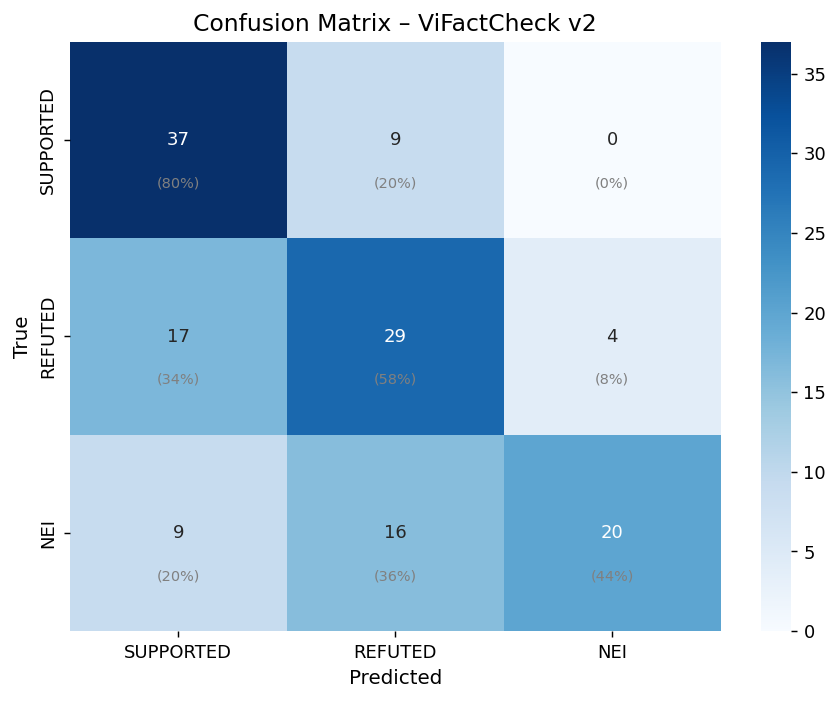

───────────────────────── 4. TRAINING CURVE ──────────────────────────


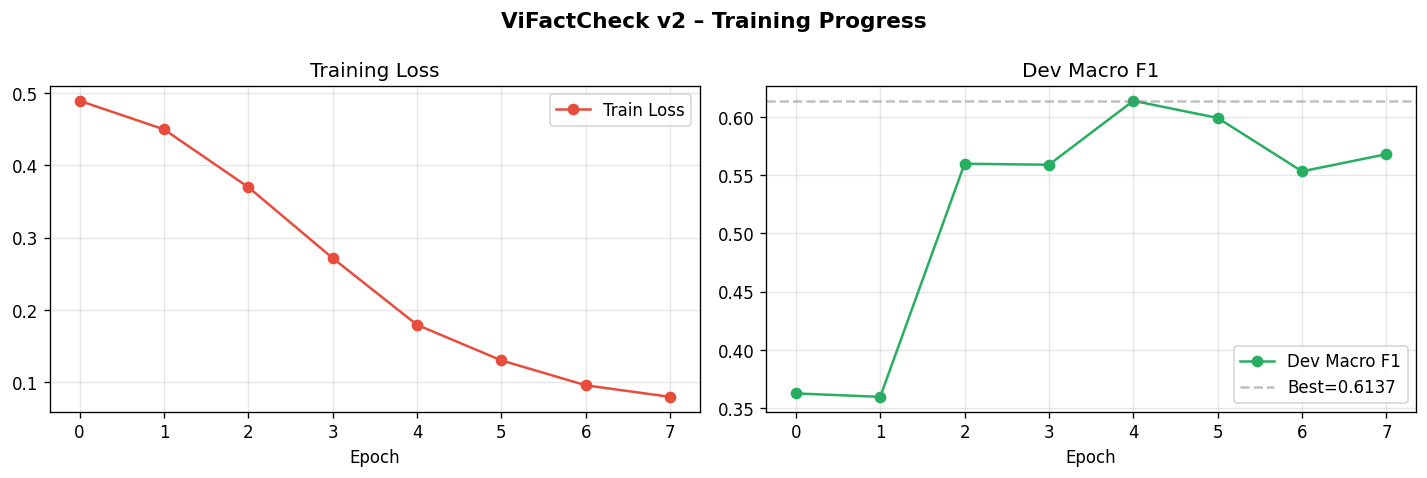

────────────────────────── 5. LỖI TIÊU BIỂU ──────────────────────────

  ── Lỗi #1 ──────────────────────────────────────────
  Claim    : Đề xuất của EVN đưa ra sau khi đơn vị tư vấn là Ban quản lý dự án điện 4 (thuộc EVN) đã rà soát nhu cầu phụ tải điện và xây dựng các thông b
  Thực tế  : REFUTED  → Dự đoán: SUPPORTED (conf=0.718, H=0.7661)
  Giải thích: Có thể nhầm số liệu giữa claim và evidence

  ── Lỗi #2 ──────────────────────────────────────────
  Claim    : Nhà máy MPE Smart Factory đã được khánh thành vào ngày 25/3 sau khoảng 10 năm xây dựng.
  Thực tế  : REFUTED  → Dự đoán: NEI (conf=0.473, H=0.9169)
  Giải thích: Có thể nhầm số liệu giữa claim và evidence; Evidence đủ nhưng mô
hình không tìm được liên kết

  ── Lỗi #3 ──────────────────────────────────────────
  Claim    : Công ty DGC dự kiến đầu tư tổng cộng 550 tỷ đồng vào các dự án xây dựng trong năm 2023.
  Thực tế  : SUPPORTED  → Dự đoán: REFUTED (conf=0.534, H=1.0132)
  Giải thích: Có thể nhầm số liệu giữa claim và 

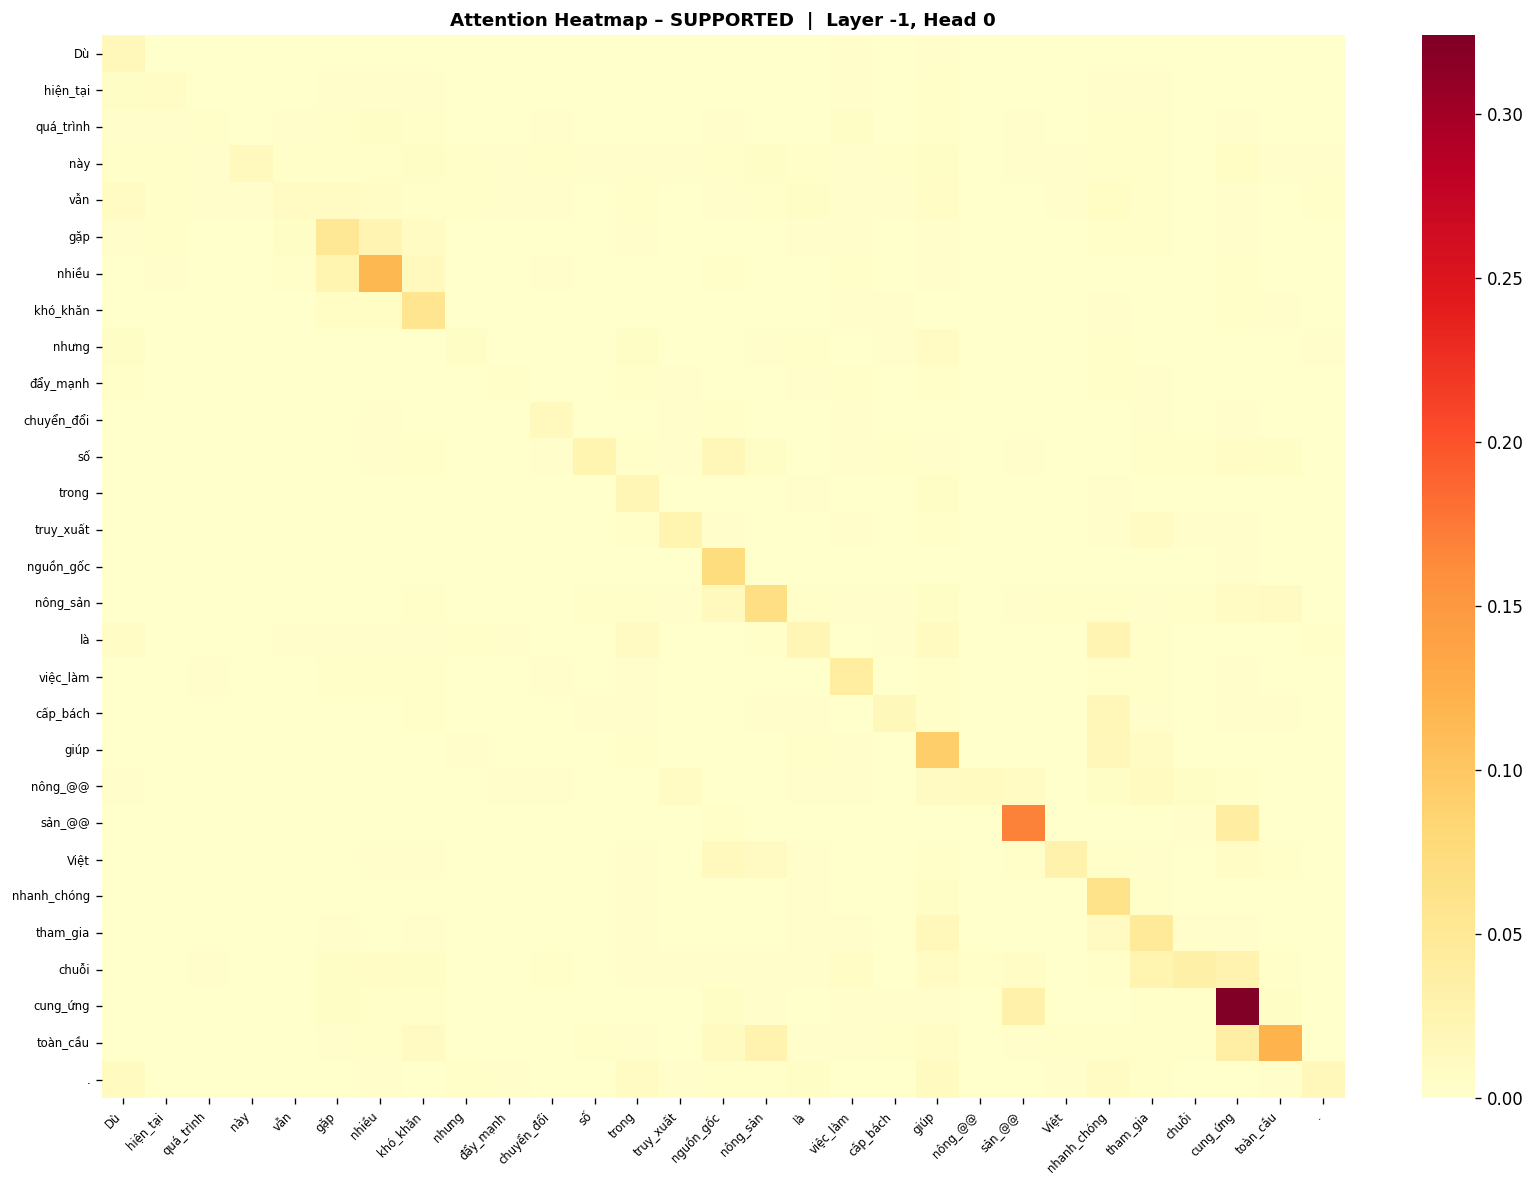

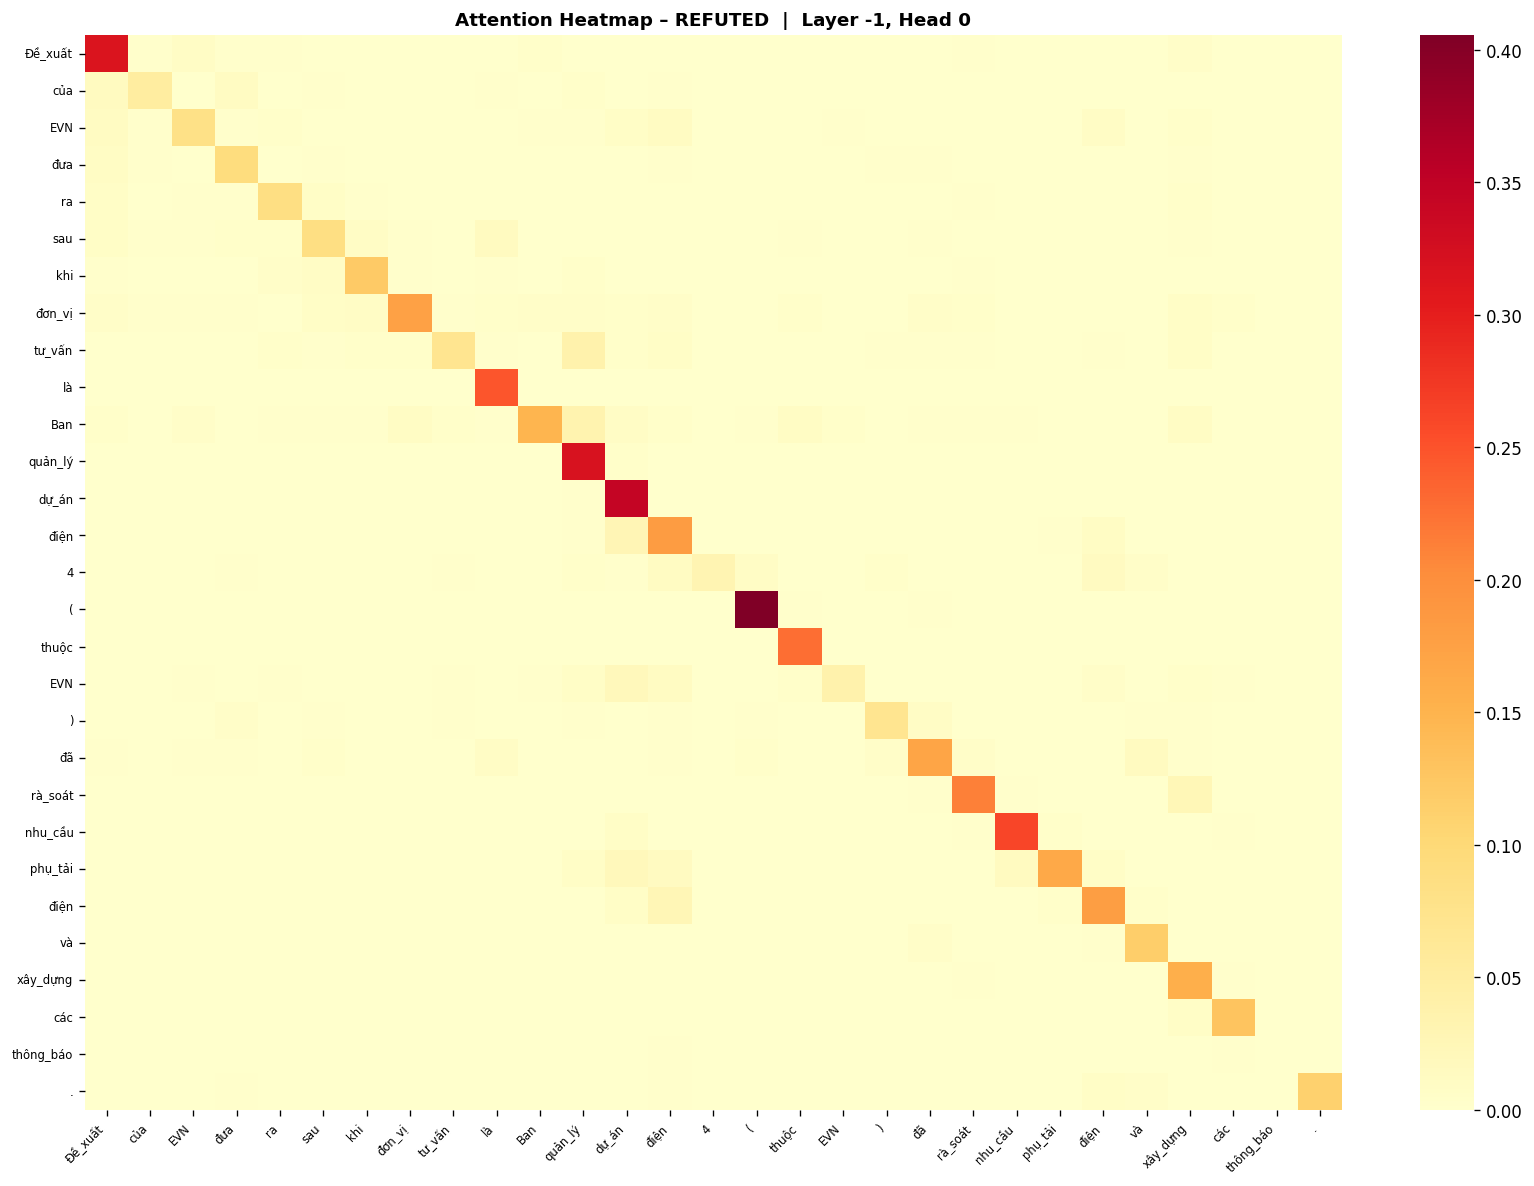

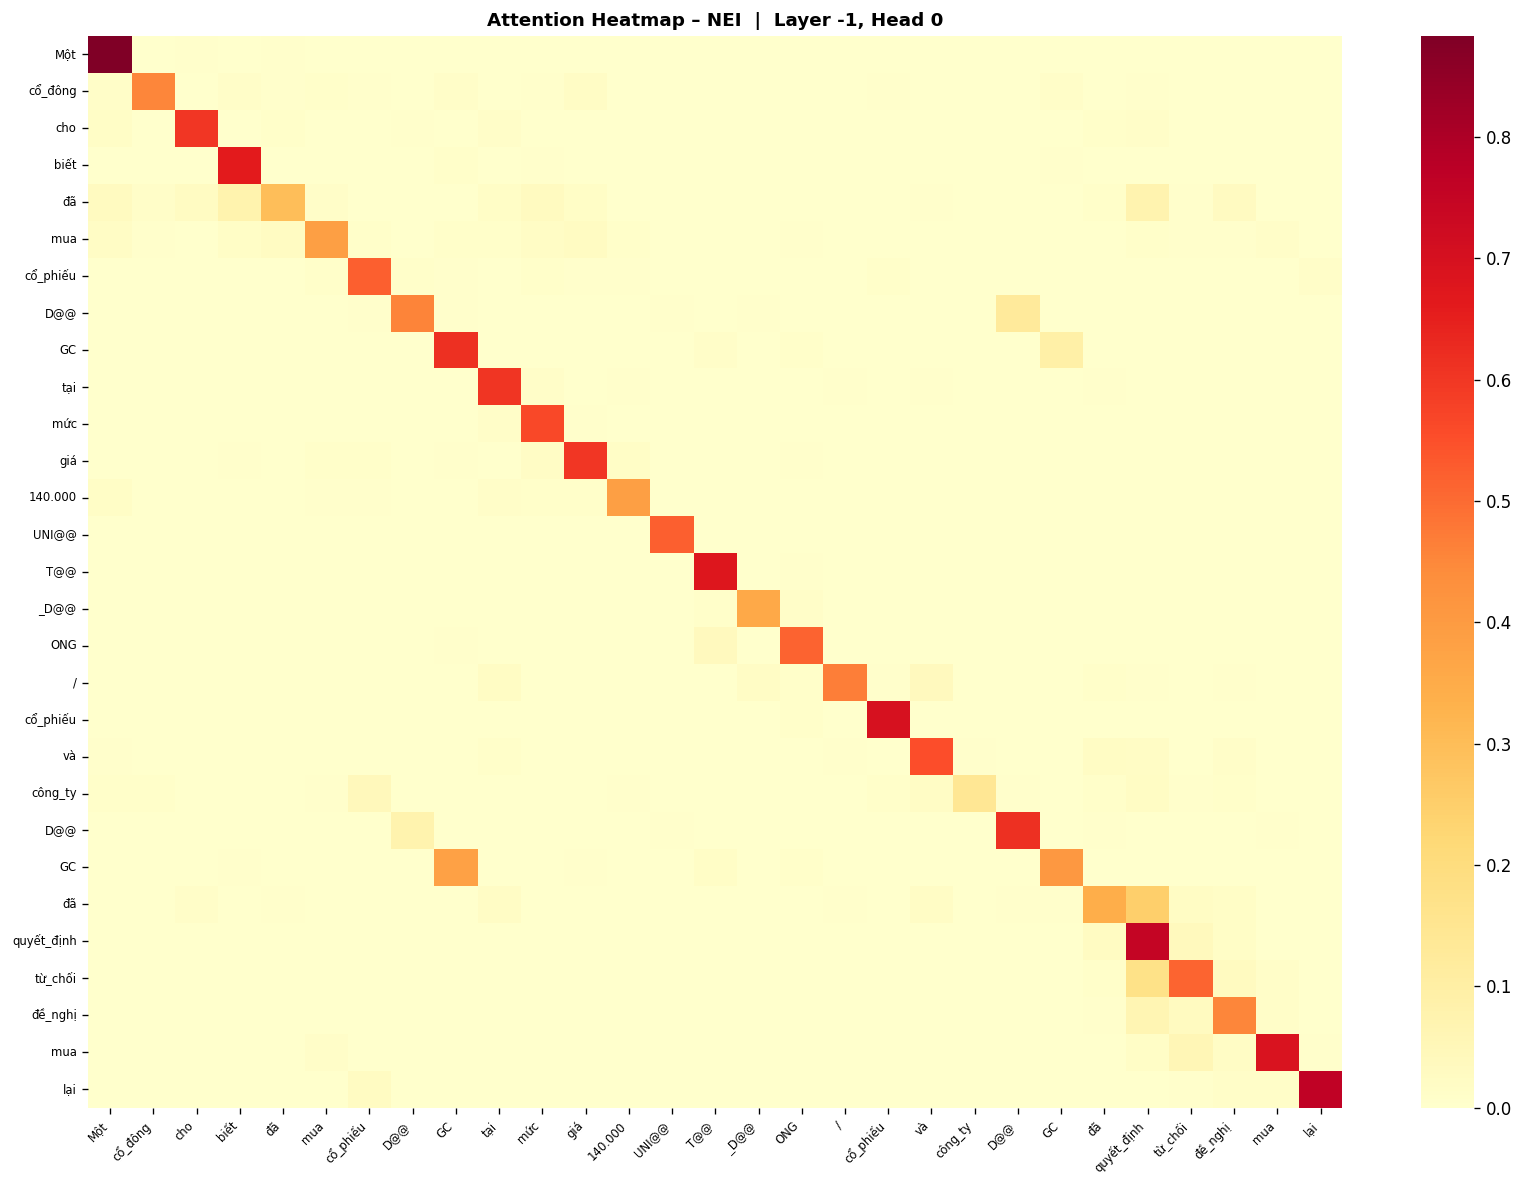

────────────────────────── 8. ENTITY GRAPH ───────────────────────────


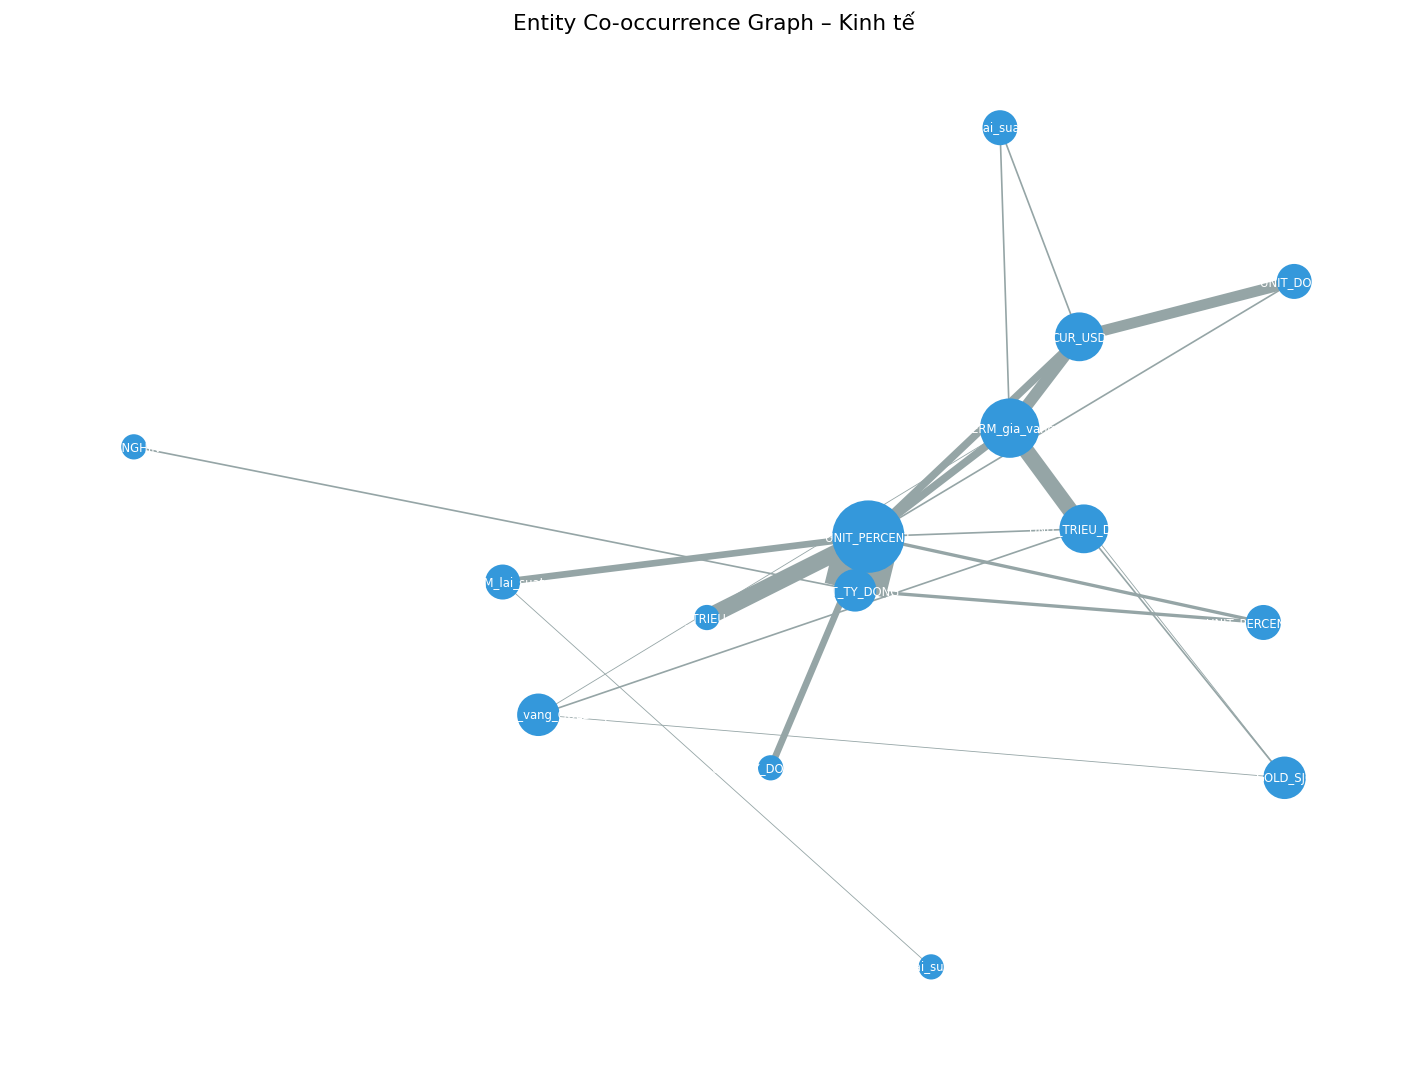

───────────────────────── 9. ATTENTION GRID ──────────────────────────


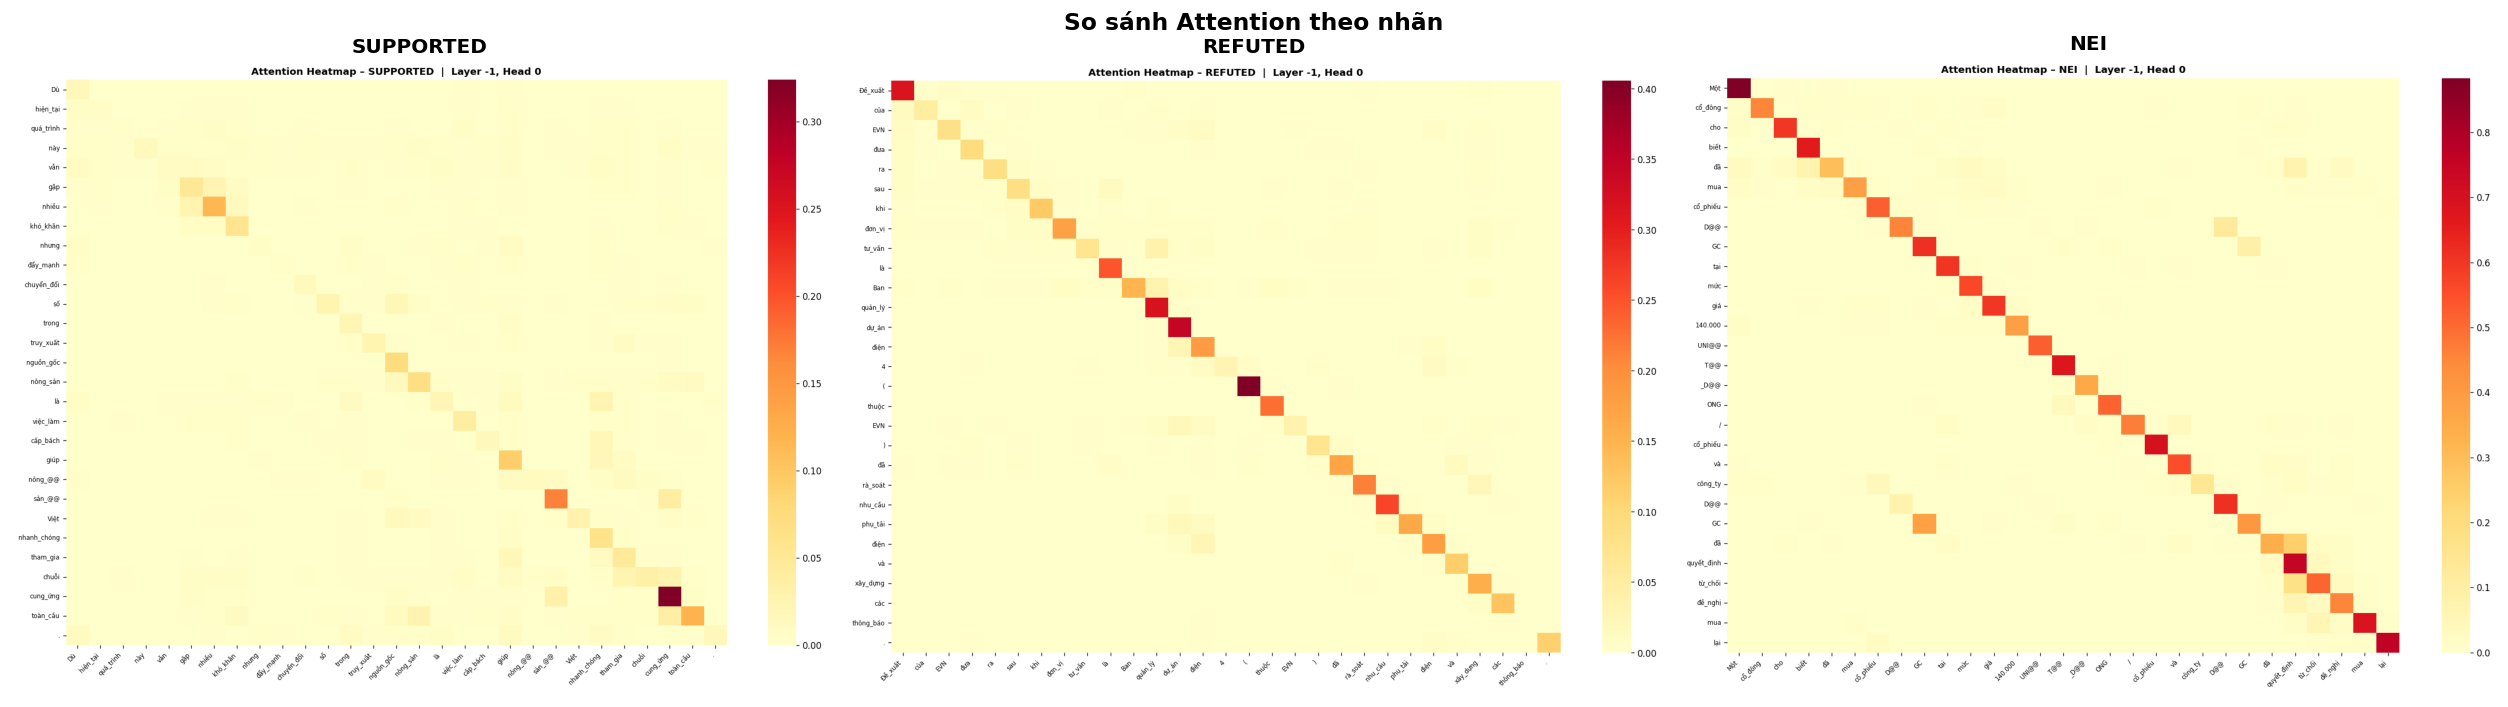

═══════════════════════════════ ✅ XONG ═══════════════════════════════
  Tất cả kết quả tại: /content/vifactcheck_v2


In [ ]:
import sys
from IPython.display import display, Image as IPImage, HTML
from pathlib import Path
import json, textwrap

def sep(title="", char="─", width=70):
    """In đường phân cách đẹp"""
    if title:
        title_str = f" {title} "
        pad = (width - len(title_str)) // 2
        line = char * pad + title_str + char * (width - pad - len(title_str))
        print(line)
    else:
        print(char * width)

# ====================== SỬA LẠI PHẦN HIỂN THỊ ======================
def display_results(output_dir: str = CFG["output_dir"]) -> None:
    out = Path(output_dir)
    in_nb = "ipykernel" in sys.modules

    def show_img(path, caption=""):
        if not Path(path).exists():
            print(f"  [Chưa có: {Path(path).name}]")
            return
        if in_nb:
            display(IPImage(filename=str(path)))
            if caption:
                display(HTML(f"<p style='text-align:center;color:gray'>{caption}</p>"))
        else:
            print(f"  → Ảnh: {path}")

    sep("📊 KẾT QUẢ VIFACTCHECK v2", "═", 80)   # ← đã sửa
    print()

    # 1. Dữ liệu
    sep("1. DỮ LIỆU ĐÃ XỬ LÝ")
    for pf in sorted(out.glob("*_processed.parquet")):
        df = pd.read_parquet(pf)
        name = pf.stem.replace("_processed", "")
        dist = {ID2LABEL[int(k)]: v for k, v in df["label"].value_counts().sort_index().items()}
        print(f"  {name}: {len(df)} mẫu | {dist}")

    # 2. Evaluation
    sep("2. EVALUATION REPORT")
    rp = out/"evaluation_report.txt"
    print(open(rp, encoding="utf-8").read() if rp.exists() else "  Chưa có – chạy Phase 4.")

    # 3. Confusion Matrix
    sep("3. CONFUSION MATRIX"); show_img(out/"confusion_matrix.png")

    # 4. Training Curve
    sep("4. TRAINING CURVE"); show_img(out/"training_history.png")

    # 5. Error Analysis
    sep("5. LỖI TIÊU BIỂU")
    ep = out/"error_analysis.csv"
    if ep.exists():
        err_df = pd.read_csv(ep)
        for i, row in err_df.head(5).iterrows():
            print(f"\n  ── Lỗi #{i+1} ──────────────────────────────────────────")
            print(f"  Claim    : {str(row['claim'])[:140]}")
            print(f"  Thực tế  : {row['true_label']}  → Dự đoán: {row['pred_label']} (conf={row['pred_conf']}, H={row['entropy']})")
            print(f"  Giải thích: {textwrap.fill(str(row['explanation']), 68)}")

    # 6. Numerical
    sep("6. NUMERICAL REASONING")
    np_path = out/"numerical_check.csv"
    if np_path.exists():
        ndf = pd.read_csv(np_path)
        print(f"  Tổng mẫu số: {len(ndf)} | Đúng: {ndf['correct'].sum()} ({ndf['correct'].mean():.1%})")
        print(f"  Avg entropy: {ndf['entropy'].astype(float).mean():.4f}")
        g = ndf.groupby("correct")["num_attn_recv"].mean()
        for k, v in g.items():
            print(f"  {'Đúng ✓' if k else 'Sai ✗'}: avg numeric attention = {v:.5f}")

    # 7–9. Heatmaps & Grid
    sep("7. ATTENTION HEATMAPS")
    for n in ID2LABEL.values():
        show_img(out/f"attention_heatmap_{n}.png", f"Nhãn: {n}")
    sep("8. ENTITY GRAPH"); show_img(out/"entity_graph.png")
    sep("9. ATTENTION GRID"); show_img(out/"attention_grid_comparison.png")
    sep("✅ XONG", "═")
    print(f"  Tất cả kết quả tại: {out.resolve()}")

display_results()


## Bonus – NEI Entropy Calibration

Kỹ thuật bổ sung: dùng entropy để re-calibrate dự đoán REFUTED/SUPPORTED về NEI khi mô hình không tự tin.

In [ ]:
def calibrate_nei(probs: np.ndarray, entropy_threshold: float = 0.95) -> np.ndarray:
    """
    Post-hoc calibration: nếu entropy > threshold → đổi về NEI.
    Hữu ích khi mô hình overconfident trên REFUTED/SUPPORTED với evidence yếu.
    """
    preds = probs.argmax(axis=1).copy()
    for i, p in enumerate(probs):
        h = float(-np.sum(p * np.log(p + 1e-9)))
        if h > entropy_threshold and preds[i] != LABEL2ID["NEI"]:
            preds[i] = LABEL2ID["NEI"]
    return preds


# Demo calibration nếu đã có model
try:
    out = Path(CFG["output_dir"])
    pqs = list(out.glob("test_processed.parquet"))
    if pqs and (out/"model").exists():
        test_df = pd.read_parquet(pqs[0])
        trainer = FactCheckTrainer(CFG); trainer.load(str(out/"model"))
        _, probs = trainer.predict(test_df)

        from sklearn.metrics import f1_score
        preds_raw   = probs.argmax(axis=1)
        preds_calib = calibrate_nei(probs, entropy_threshold=0.95)
        labels = test_df["label"].values

        f1_raw   = f1_score(labels, preds_raw,   average="macro", zero_division=0)
        f1_calib = f1_score(labels, preds_calib, average="macro", zero_division=0)
        print(f"  Macro F1 (raw)         = {f1_raw:.4f}")
        print(f"  Macro F1 (NEI-calibr.) = {f1_calib:.4f}")
        n_changed = (preds_raw != preds_calib).sum()
        print(f"  Số mẫu được chuyển về NEI: {n_changed}")
    else:
        print("  Chưa có model – chạy Phase 2 trước.")
except Exception as e:
    print(f"  Calibration demo skip: {e}")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.pooler.dense.weight     | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.pooler.dense.bias       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initia

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  Macro F1 (raw)         = 0.6054
  Macro F1 (NEI-calibr.) = 0.5058
  Số mẫu được chuyển về NEI: 43
